In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
df = pd.read_csv("tech_store_sales_practice.csv")
df.info()
df.describe()
df.head()
df["Date"] = pd.to_datetime(df["Date"])


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Date             150 non-null    str    
 1   Category         150 non-null    str    
 2   Product          150 non-null    str    
 3   Region           150 non-null    str    
 4   Units_Sold       150 non-null    int64  
 5   Unit_Price_USD   150 non-null    int64  
 6   Revenue_USD      150 non-null    int64  
 7   Ad_Spend_USD     150 non-null    float64
 8   Customer_Rating  150 non-null    float64
 9   Returned_Units   150 non-null    int64  
dtypes: float64(2), int64(4), str(4)
memory usage: 11.8 KB


# Category Level Performance

task 1: Calculate total revenue and units sold per category

task2: Plot a pie chart or horizonatal bar chart showing category revenue share

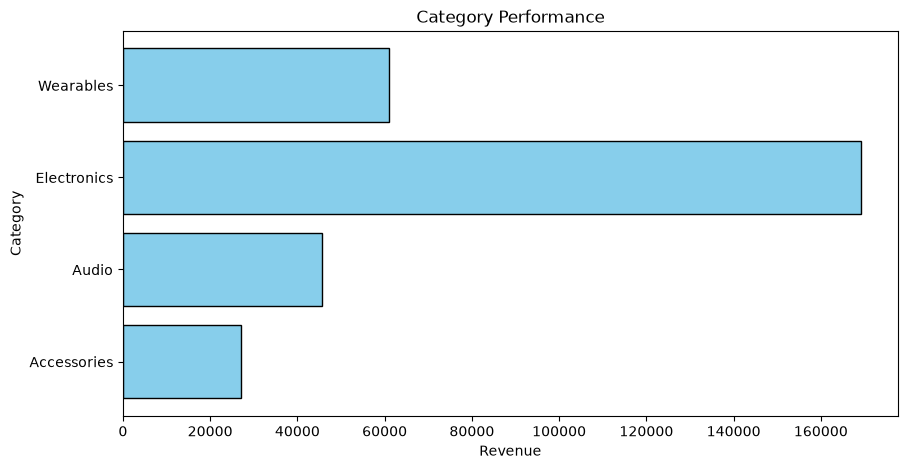

In [ ]:
total_revenue =df.groupby("Category").agg({
    "Revenue_USD": "sum",
    "Units_Sold": "mean"
}).reset_index()

plt.figure(figsize=(10, 5))
plt.barh(
    total_revenue["Category"],
    total_revenue["Revenue_USD"],
    color="skyblue",
    edgecolor="black"
)

plt.xlabel("Revenue")
plt.ylabel("Category")
plt.title("Category Performance")

plt.show()


# Ad Spend ROI Analysis

Task 1: Plot a scatter plot comparing Ad_Spend_USD vs Revenue_USD


Task 2: Calculate revenue per dollar of ad spend (Revenue_USD / Ad_Spend_USD).

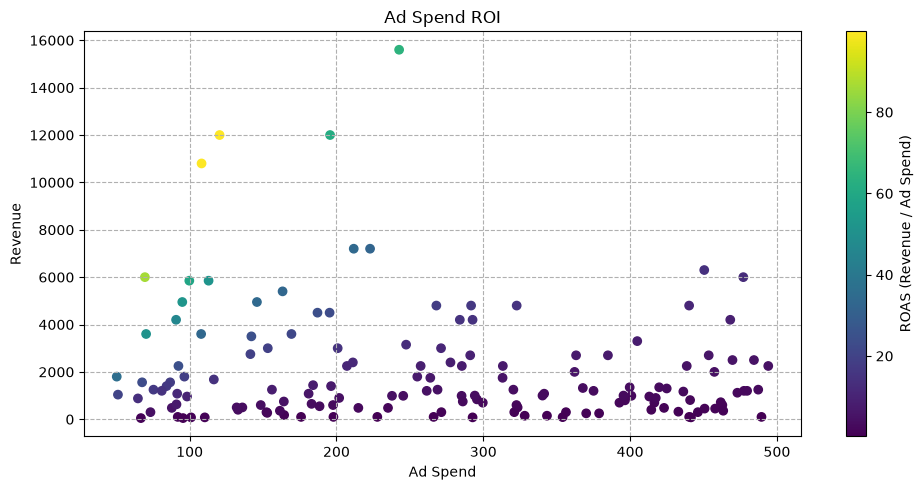

In [33]:
df["ROAS"] = df["Revenue_USD"] / df["Ad_Spend_USD"]

plt.figure(figsize=(10, 5))
plt.scatter(
    df["Ad_Spend_USD"],
    df["Revenue_USD"],
    c=df["ROAS"],
    label="Revenue_USD"
)
plt.colorbar(label="ROAS (Revenue / Ad Spend)")
plt.xlabel("Ad Spend")
plt.ylabel("Revenue")
plt.title("Ad Spend ROI")
plt.tight_layout()
plt.grid(True, linestyle="--")

plt.show()


# Dual-Axis Chart

Task: Aggregate monthly sales to plot Total Revenue (line/bar) and Average Customer Rating (line) over time.

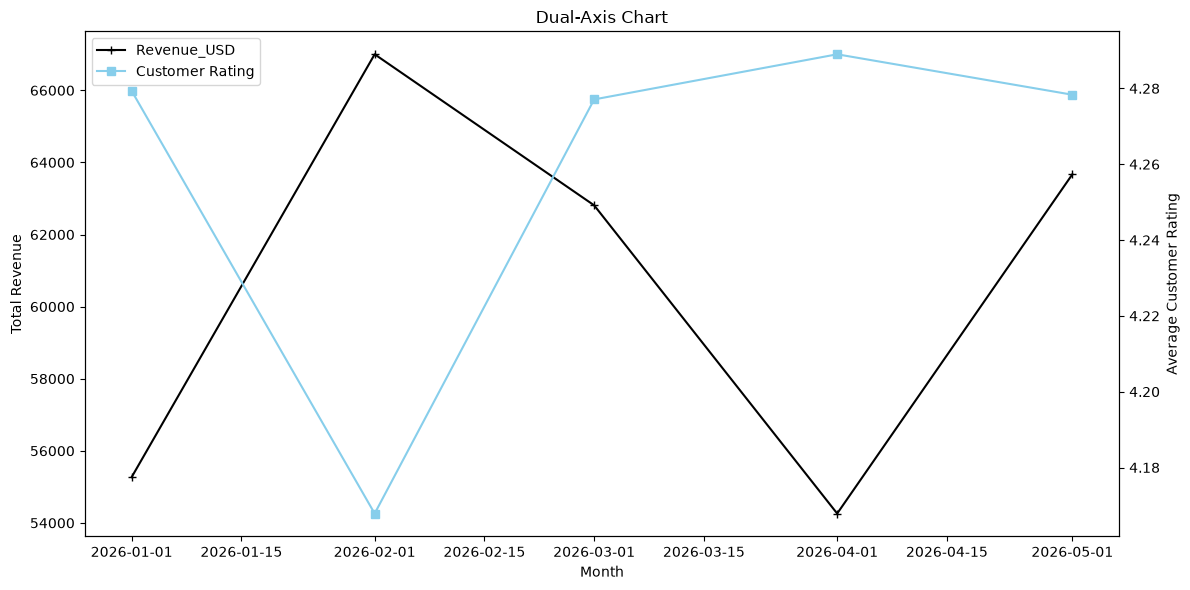

In [30]:
monthly_agrregate = (df.groupby(df["Date"].dt.to_period("M")).agg({
    "Revenue_USD": "sum",
    "Customer_Rating": "mean"
})
)

fig, ax = plt.subplots(figsize=(12, 6))

line1 = ax.plot(
    monthly_agrregate.index.to_timestamp(),
    monthly_agrregate["Revenue_USD"],
    marker="+",
    color="black",
    label="Revenue_USD"
)

ax.set_xlabel("Month")
ax.set_ylabel("Total Revenue")

ax2 = ax.twinx()

line2 = ax2.plot(
    monthly_agrregate.index.to_timestamp(),
    monthly_agrregate["Customer_Rating"],
    color="skyblue",
    marker="s",
    label="Customer Rating"
)
ax2.set_ylabel("Average Customer Rating")

lines = line1 + line2
label = (l.get_label() for l in lines)
ax.legend(lines, label,  loc="upper left")

plt.title("Dual-Axis Chart")
plt.tight_layout()

plt.show()





# Return Rate Investigation

Task 1: Calculate the return rate percentage per product: (Returned_Units.sum() / Units_Sold.sum()) * 100.

Task 2: Find which product has the highest return rate.

In [31]:
product_summary = (df.groupby("Product").agg({
    "Units_Sold": "sum",
    "Revenue_USD": "sum",
    "Customer_Rating": "mean",
    "Returned_Units": "sum", 
})
).reset_index()

product_summary["Return_Rate"] = (product_summary["Returned_Units"] / product_summary["Units_Sold"]) * 100
print(product_summary["Return_Rate"])

0    4.545455
1    1.265823
2    1.515152
3    2.307692
4    0.662252
5    1.470588
6    0.000000
7    2.083333
8    0.000000
9    3.846154
Name: Return_Rate, dtype: float64
